# 6. Decision Trees and Ensemble Learning

In [2]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'

In [3]:
!wget $data

--2026-09-09 04:44:56--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 182489 (178K) [text/plain]
Saving to: ‘CreditScoring.csv.1’

CreditScoring.csv.1 100%[===================>] 178.21K  --.-KB/s    in 0.003s  

2026-09-09 04:44:57 (66.2 MB/s) - ‘CreditScoring.csv.1’ saved [182489/182489]



In [3]:
df = pd.read_csv("CreditScoring.csv")

In [4]:
df.head()


,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [5]:
df.columns = df.columns.str.lower()

In [6]:
df.status.value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

In [7]:
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

In [8]:
df.status = df.status.map(status_values)

In [9]:
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [10]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [11]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [12]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace = 99999999, value=np.nan)

In [13]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [14]:
df [df.status != 'unk'].reset_index(drop=True)

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129.0,0.0,0.0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131.0,0.0,0.0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200.0,3000.0,0.0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182.0,2500.0,0.0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107.0,0.0,0.0,310,910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4449,default,1,rent,60,39,married,no,fixed,69,92.0,0.0,0.0,900,1020
4450,ok,22,owner,60,46,married,no,fixed,60,75.0,3000.0,600.0,950,1263
4451,default,0,owner,24,37,married,no,partime,60,90.0,3500.0,0.0,500,963
4452,ok,0,rent,48,23,single,no,freelance,49,140.0,0.0,0.0,550,550


In [15]:
from sklearn.model_selection import train_test_split

In [16]:
df_full_train, df_test = train_test_split(df,test_size = 0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train,test_size = 0.25, random_state=11)

In [17]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [18]:
y_train = (df_train.status == 'default').astype(int).values
y_val = (df_val.status == 'default').astype(int).values
y_test = (df_test.status == 'default').astype(int).values

In [19]:
del df_train['status']
del df_val['status']
del df_test['status']


## Decision Tree

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

In [21]:
df_train.head()

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,3,rent,36,61,married,no,fixed,41,57.0,12000.0,0.0,2500,3559
1,5,rent,48,30,separated,yes,partime,39,41.0,0.0,0.0,1300,1600
2,15,owner,60,32,divorced,no,freelance,35,0.0,6000.0,3300.0,1550,1612
3,2,rent,12,47,married,yes,fixed,103,426.0,0.0,0.0,350,450
4,6,parents,48,32,single,yes,fixed,35,85.0,0.0,0.0,1100,1330


In [22]:
train_dicts = df_train.to_dict(orient="records")

In [23]:
train_dicts[0]

{'seniority': 3,
 'home': 'rent',
 'time': 36,
 'age': 61,
 'marital': 'married',
 'records': 'no',
 'job': 'fixed',
 'expenses': 41,
 'income': 57.0,
 'assets': 12000.0,
 'debt': 0.0,
 'amount': 2500,
 'price': 3559}

In [24]:
dv=DictVectorizer(sparse=False)

In [25]:
X_train = dv.fit_transform(train_dicts)

In [26]:
type(X_train)

numpy.ndarray

In [27]:
dv.get_feature_names_out()

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'marital=divorced', 'marital=married',
       'marital=separated', 'marital=single', 'marital=unk',
       'marital=widow', 'price', 'records=no', 'records=yes', 'seniority',
       'time'], dtype=object)

In [28]:
dv

DictVectorizer(sparse=False)

In [29]:
dt = DecisionTreeClassifier()
dt.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [30]:
val_dicts = df_val.to_dict(orient="records")

In [31]:
X_val = dv.transform(val_dicts)

In [32]:
y_val_pred = dt.predict_proba(X_val)[ :, 1]

In [33]:
roc_auc_score (y_val,y_val_pred)

0.6546496248408509

In [34]:
dt = DecisionTreeClassifier(max_depth=3)
dt.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [35]:
y_val_pred = dt.predict_proba(X_val)[ :, 1]

In [36]:
roc_auc_score (y_val,y_val_pred)

0.7530253773223402

In [37]:
from sklearn.tree import export_text

In [38]:
print(export_text(dt, feature_names = dv.get_feature_names_out()))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- income <= 50.50
|   |   |   |--- class: 1
|   |   |--- income >  50.50
|   |   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- income <= 99.50
|   |   |   |--- class: 1
|   |   |--- income >  99.50
|   |   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=partime <= 0.50
|   |   |--- income <= 73.50
|   |   |   |--- class: 0
|   |   |--- income >  73.50
|   |   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- time <= 27.00
|   |   |   |--- class: 0
|   |   |--- time >  27.00
|   |   |   |--- class: 1



### Decision Tree Hyperparameter Tuning

In [39]:
for d in [1,2,3,4,5,6, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth=d)
    dt.fit(X_train,y_train)
    y_val_pred = dt.predict_proba(X_val)[ :, 1]
    auc = roc_auc_score (y_val,y_val_pred)
    print(d,auc)
    

1 0.6131750701491985
2 0.6876073869887143
3 0.7530253773223402
4 0.7650836227889096
5 0.7630440425716016
6 0.75805325158531
10 0.6887353366543467
15 0.6753791765040358
20 0.6432217950778131
None 0.6613400660082325


In [40]:
for d in [4,5,6]:
    for s in[1,2,5,10, 20, 100,500]:

        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
        dt.fit(X_train,y_train)
        y_val_pred = dt.predict_proba(X_val)[ :, 1]
        auc = roc_auc_score (y_val,y_val_pred)
        print(d,s, auc)
            


4 1 0.7650836227889096
4 2 0.7650836227889096
4 5 0.7650836227889096


4 10 0.7594562355529735
4 20 0.7696139630897787
4 100 0.7582602998800974
4 500 0.6713680020766635
5 1 0.7621756758427174
5 2 0.761597794781147
5 5 0.7640112980382947
5 10 0.7636929999134723
5 20 0.7695737895400439
5 100 0.7759490228556596
5 500 0.6713680020766635
6 1 0.7536434319336456
6 2 0.7609179347087108
6 5 0.7676732716102795
6 10 0.7837396012311647
6 20 0.7925376086230979
6 100 0.7834954696596992
6 500 0.6713680020766635


### XGB

In [41]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [42]:
import xgboost as xgb

In [43]:
features = dv.get_feature_names_out().tolist()

In [44]:
type(features)

list

In [45]:
dtrain = xgb.DMatrix(X_train, label= y_train, feature_names = features)
dval = xgb.DMatrix(X_val, label= y_val, feature_names = features)

In [46]:
xgb_params = {
    'eta': 0.3,
    'max_depth':6,
    'min_child_weight':1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread':8,
    'seed': 1,
    'verbosity': 1   
}

In [47]:
watchlist = [(dtrain, 'train'),(dval, 'val')]

In [48]:
%%capture output
model = xgb.train(xgb_params, dtrain, evals =watchlist, verbose_eval = 5, num_boost_round=200)

In [49]:
s = output.stdout

In [50]:
y_pred = model.predict(dval)

In [51]:
roc_auc_score(y_val, y_pred)

0.8105168172659737

In [52]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [53]:
df_score = parse_xgb_output(output)

In [54]:
df_score

,num_iter,train_auc,val_auc
0,0,0.85953,0.77414
1,5,0.92535,0.82037
2,10,0.95219,0.82791
3,15,0.96685,0.82375
4,20,0.97502,0.82233
5,25,0.98167,0.81895
6,30,0.98589,0.82026
7,35,0.98983,0.82026
8,40,0.99316,0.81663
9,45,0.99586,0.81735


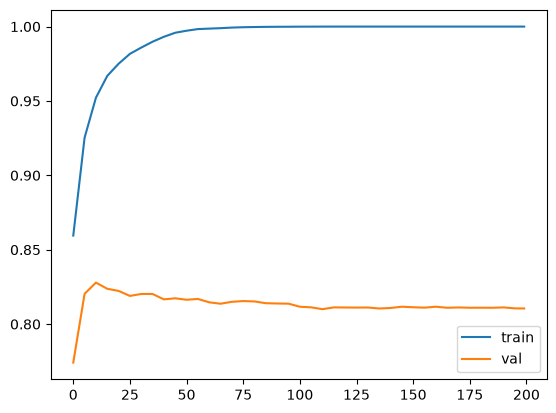

In [55]:
plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

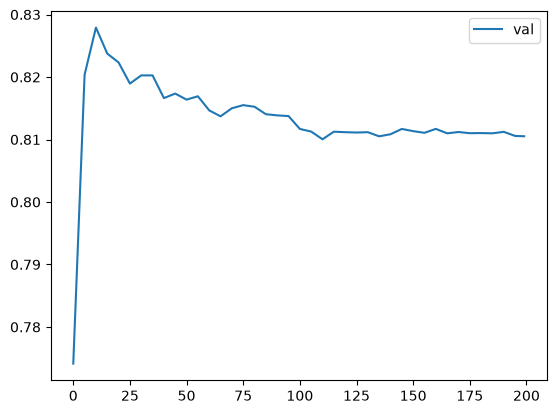

In [56]:

plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

### XGB Hyperparameter Tuning

In [57]:
scores ={}

In [70]:
%%capture output
xgb_params = {
    'eta': 0.3,
    'max_depth':6,
    'min_child_weight':1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread':8,
    'seed': 1,
    'verbosity': 1   
}

model = xgb.train(xgb_params, dtrain, evals =watchlist, verbose_eval = 5, num_boost_round=200)

In [71]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.3'

In [72]:
scores

{'eta=1':     num_iter  train_auc  val_auc
 0          0    0.85953  0.77414
 1          5    0.95353  0.81122
 2         10    0.98198  0.81347
 3         15    0.99486  0.80487
 4         20    0.99819  0.81301
 5         25    0.99974  0.80403
 6         30    0.99996  0.80238
 7         35    0.99999  0.79971
 8         40    1.00000  0.79426
 9         45    1.00000  0.79202
 10        50    1.00000  0.79481
 11        55    1.00000  0.79549
 12        60    1.00000  0.79352
 13        65    1.00000  0.79425
 14        70    1.00000  0.79285
 15        75    1.00000  0.79369
 16        80    1.00000  0.79382
 17        85    1.00000  0.79237
 18        90    1.00000  0.79330
 19        95    1.00000  0.79470
 20       100    1.00000  0.79610
 21       105    1.00000  0.79607
 22       110    1.00000  0.79727
 23       115    1.00000  0.79782
 24       120    1.00000  0.79631
 25       125    1.00000  0.79743
 26       130    1.00000  0.79753
 27       135    1.00000  0.79686
 28  

In [73]:
scores.keys()

dict_keys(['eta=1', 'eta=0.1', 'eta=0.3'])

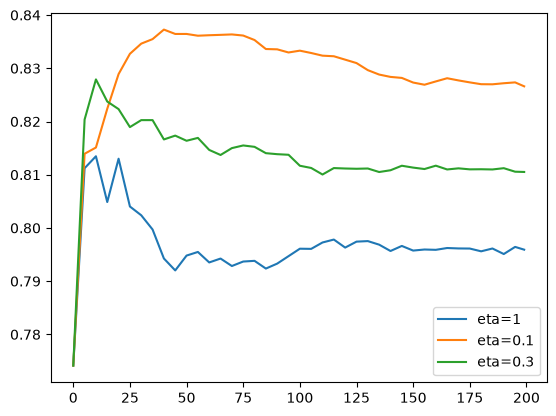

In [74]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)
plt.legend()

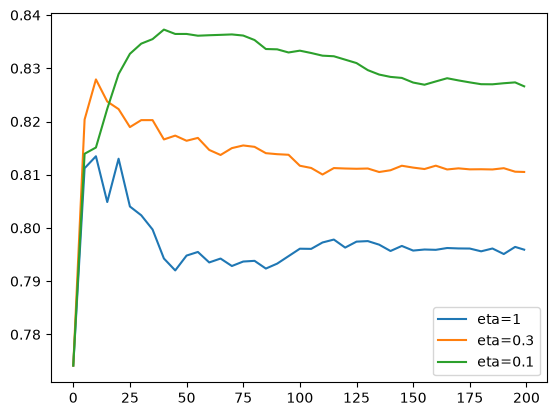

In [75]:
etas = ['eta=1', 'eta=0.3', 'eta=0.1']

for eta in etas:
    df_score = scores[eta]
    plt.plot(df_score.num_iter, df_score.val_auc, label = eta)

plt.legend()

### Model Selection
among DT, RF, Xgb, Xgb is the best model, so we are going to use all train(including evaluation to train the model and evaluate using test dataset)

In [77]:
df_full_train = df_full_train.reset_index(drop=True)

In [78]:
y_full_train = (df_full_train.status == 'default').astype(int).values

In [79]:
del df_full_train['status']

In [80]:
dict_full_train = df_full_train.to_dict(orient= 'records')

In [81]:
dv = DictVectorizer(sparse=False)

In [82]:
X_full_train = dv.fit_transform(dict_full_train)

In [84]:
dict_test = df_test.to_dict(orient = 'records')

In [86]:
X_test = dv.transform(dict_test)

In [90]:
features = dv.get_feature_names_out().tolist()

dfulltrain = xgb.DMatrix(X_full_train, label= y_full_train, feature_names = features)
dtest = xgb.DMatrix(X_test, feature_names =features)

In [91]:
xgb_params = {
    'eta': 0.3,
    'max_depth':3,
    'min_child_weight':1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread':8,
    'seed': 1,
    'verbosity': 1   
}

model = xgb.train(xgb_params, dfulltrain, verbose_eval = 5, num_boost_round=200)

In [92]:
y_pred = model.predict(dtest)

In [94]:
roc_auc_score(y_test, y_pred)

0.8167202572347267